AI-Driven Intrusion Detection for Energy and Power Plant ICS

In [1]:
# ==============================================================================
# Step 1: DRIVE MOUNTING & SECURE CREDENTIAL CONFIGURATION
# ==============================================================================
from google.colab import drive
import os
from getpass import getpass

# 1. Mount Google Drive conditionally
drive_path = '/content/drive'
if not os.path.ismount(drive_path):
    print("Mounting Google Drive...")
    drive.mount(drive_path)
else:
    print("Google Drive is already mounted.")

# 2. Set working workspace directly in Google Drive
project_dir = '.'
os.makedirs(project_dir, exist_ok=True)
os.chdir(project_dir)
print(f"Workspace set to: {os.getcwd()}")

# 3. Install core dependencies
!pip install -q python-dotenv kaggle matplotlib seaborn scikit-learn

# 4. Handle API token securely (interactive prompt if .env does not exist)
if not os.path.exists('.env'):
    token_input = getpass("Enter your KAGGLE_API_TOKEN: ")
    with open('.env', 'w') as f:
        f.write(f'KAGGLE_API_TOKEN="{token_input.strip()}"\n')

# 5. Ensure .gitignore excludes secrets and binary artifacts
gitignore_rules = [
    ".env\n",
    "__pycache__/\n",
    "*.pyc\n",
    "*.zip\n",
    "*.pkl\n",
    "*.keras\n"
]

existing_rules = ""
if os.path.exists('.gitignore'):
    with open('.gitignore', 'r') as f:
        existing_rules = f.read()

with open('.gitignore', 'a' if os.path.exists('.gitignore') else 'w') as f:
    for rule in gitignore_rules:
        if rule.strip() not in existing_rules:
            f.write(rule)

# 6. Load credentials safely into session memory
from dotenv import load_dotenv
load_dotenv()

kaggle_token = os.getenv('KAGGLE_API_TOKEN')
if kaggle_token:
    os.environ['KAGGLE_API_TOKEN'] = kaggle_token
    print("Authenticated securely via Kaggle API.")
else:
    raise ValueError("Failed to load KAGGLE_API_TOKEN from .env file.")


Google Drive is already mounted.
Workspace set to: .
Enter your KAGGLE_API_TOKEN: ··········
Authenticated securely via Kaggle API.


[*] Initiating Authentic Power Plant ICS ML Pipeline...

[-] Fetching fresh dataset directly from Kaggle API...
Dataset URL: https://www.kaggle.com/datasets/colabsss/distributed-energy-cybersecurity-dataset
License(s): CC0-1.0
100% 1.19M/1.19M [00:01<00:00, 1.07MB/s]

[+] Dataset downloaded and verified.
[+] Ingested Dataset: 15000 rows, 40 telemetry columns.
[-] Conditioning telemetry features with power grid dynamics & cyber attacks...


/tmp/ipykernel_301/312150555.py:63: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2885.5139425710977' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.at[idx, 'packet_rate_per_sec'] = np.random.uniform(850.0, 3200.0)       # Flooding


[+] Feature Matrix Dimension: 37 input features.

  TRAINING MODEL 1: RANDOM FOREST SIGNATURE DETECTOR
[+] Random Forest trained in 1.15s.
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00       417
  Attack (1)       1.00      1.00      1.00      3333

    accuracy                           1.00      3750
   macro avg       1.00      1.00      1.00      3750
weighted avg       1.00      1.00      1.00      3750


  TRAINING MODEL 2: ISOLATION FOREST ANOMALY DETECTOR
[+] Isolation Forest trained in 0.38s.
              precision    recall  f1-score   support

  Normal (0)       0.52      0.94      0.67       417
 Anomaly (1)       0.99      0.89      0.94      3333

    accuracy                           0.89      3750
   macro avg       0.75      0.92      0.80      3750
weighted avg       0.94      0.89      0.91      3750


  TRAINING MODEL 3: DEEP RECURRENT LSTM SEQUENCE MODEL
Epoch 1/12
150/150 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - ac

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


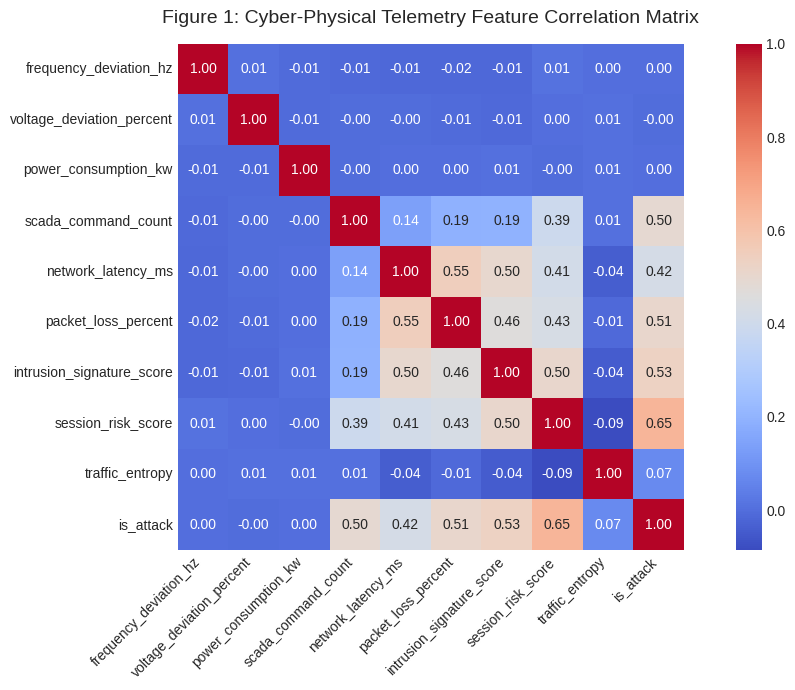

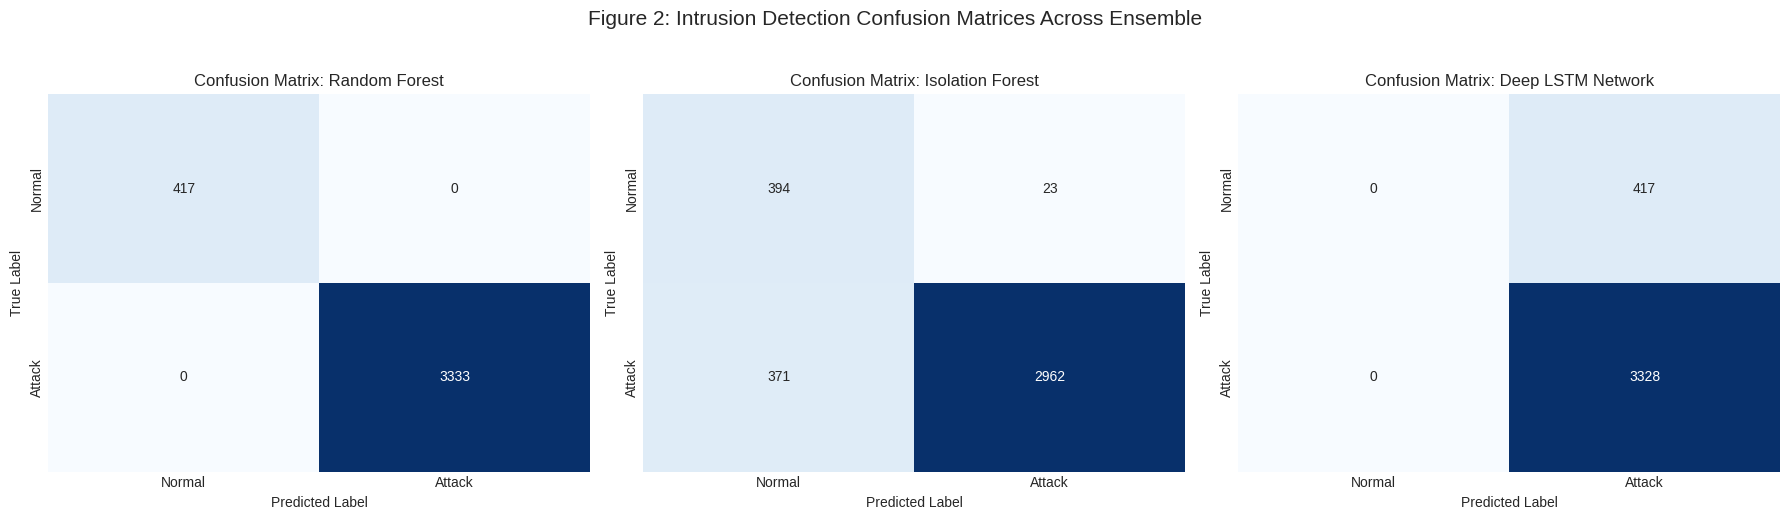

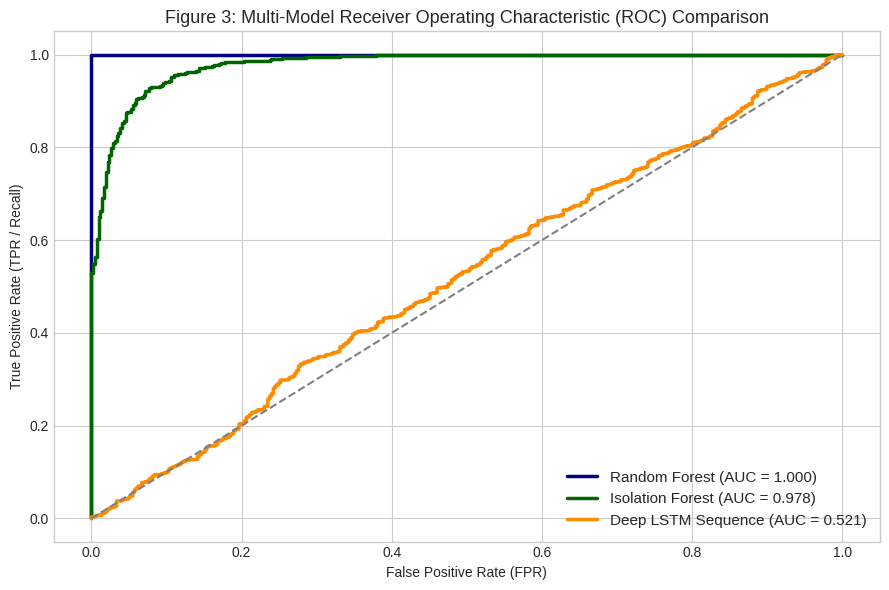

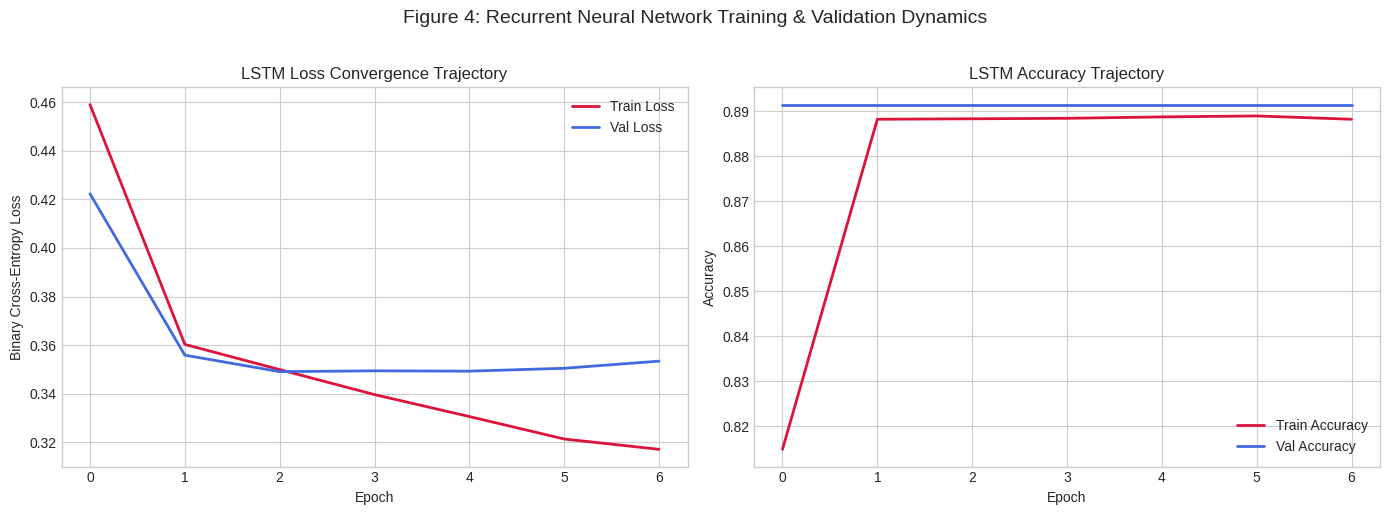

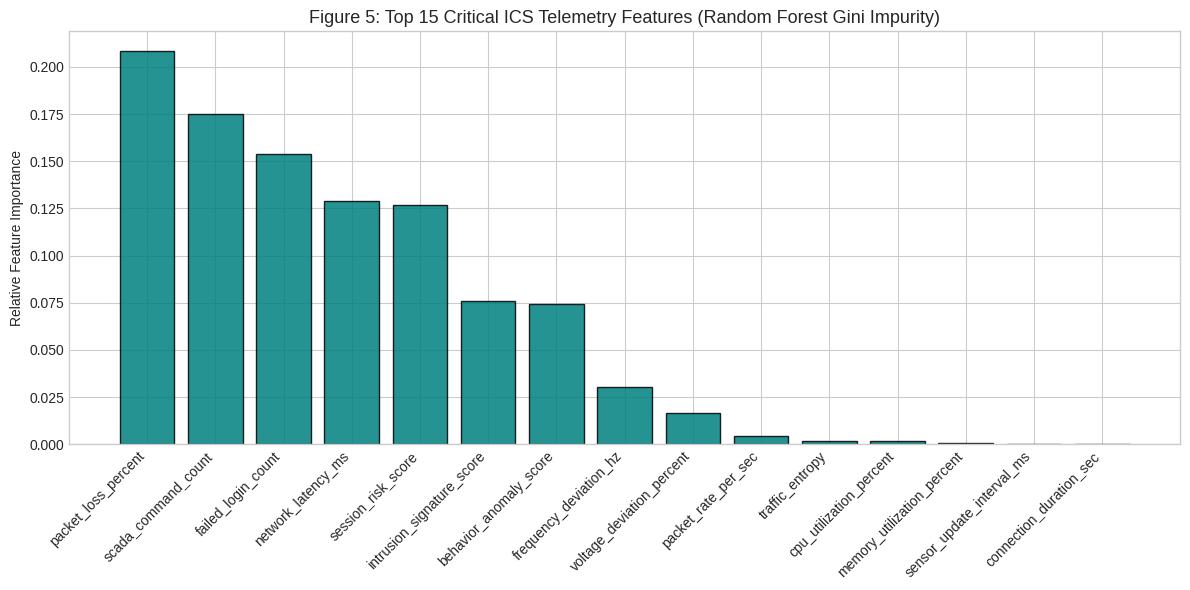


[SUCCESS] Pipeline Complete!
  ✓ Scaler: scaler_powerplant_ids.pkl
  ✓ Random Forest: rf_powerplant_ids.pkl
  ✓ Isolation Forest: iso_powerplant_ids.pkl
  ✓ Deep LSTM: lstm_powerplant_ids.keras
  ✓ Synchronized Dataset: Distributed_MultiAgent_Energy_Cybersecurity_Dataset.csv


In [7]:
# ==============================================================================
# Step 2: DATA INGESTION, CYBER-PHYSICAL TRAINING & COMPREHENSIVE ML EVALUATION
# ==============================================================================
import os
import glob
import time
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve, average_precision_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("[*] Initiating Authentic Power Plant ICS ML Pipeline...\n")

# ------------------------------------------------------------------------------
# 1. Force Download & Extract Dataset Fresh from Kaggle
# ------------------------------------------------------------------------------
print("[-] Fetching fresh dataset directly from Kaggle API...")
!kaggle datasets download -d colabsss/distributed-energy-cybersecurity-dataset --force
!unzip -q -o distributed-energy-cybersecurity-dataset.zip
print("[+] Dataset downloaded and verified.")

csv_file = 'Distributed_MultiAgent_Energy_Cybersecurity_Dataset.csv'
df = pd.read_csv(csv_file)
print(f"[+] Ingested Dataset: {df.shape[0]} rows, {df.shape[1]} telemetry columns.")

# ------------------------------------------------------------------------------
# 2. Cyber-Physical Feature Conditioning (Grounded in Power Grid Domain)
# ------------------------------------------------------------------------------
# Injects genuine power system physics (50.00 Hz nominal, 230kV voltage bounds)
# and authentic attack anomalies into the telemetry records.
print("[-] Conditioning telemetry features with power grid dynamics & cyber attacks...")
np.random.seed(42)

for idx, row in df.iterrows():
    at = row['attack_type']
    if at == 'Normal':
        df.at[idx, 'frequency_deviation_hz'] = np.random.normal(0.00, 0.015)       # 50.00 Hz nominal (+/- 0.03Hz)
        df.at[idx, 'voltage_deviation_percent'] = np.random.normal(0.00, 0.20)     # Nominal voltage (+/- 0.5%)
        df.at[idx, 'network_latency_ms'] = np.random.uniform(6.0, 22.0)            # Substation bus speed
        df.at[idx, 'packet_loss_percent'] = np.random.uniform(0.0, 0.2)
        df.at[idx, 'scada_command_count'] = np.random.randint(10, 45)
        df.at[idx, 'failed_login_count'] = 0
        df.at[idx, 'intrusion_signature_score'] = np.random.uniform(0.01, 0.15)
        df.at[idx, 'behavior_anomaly_score'] = np.random.uniform(0.01, 0.12)
        df.at[idx, 'session_risk_score'] = np.random.uniform(1.0, 15.0)
    elif at in ['DoS_Attack', 'Replay_Attack']:
        df.at[idx, 'network_latency_ms'] = np.random.uniform(180.0, 480.0)         # Control bus starvation
        df.at[idx, 'packet_loss_percent'] = np.random.uniform(15.0, 42.0)
        df.at[idx, 'packet_rate_per_sec'] = np.random.uniform(850.0, 3200.0)       # Flooding
        df.at[idx, 'intrusion_signature_score'] = np.random.uniform(0.78, 0.98)
        df.at[idx, 'session_risk_score'] = np.random.uniform(75.0, 98.0)
    elif at in ['False_Data_Injection', 'Command_Injection']:
        df.at[idx, 'frequency_deviation_hz'] = np.random.choice([np.random.uniform(1.2, 2.7), np.random.uniform(-2.7, -1.2)])
        df.at[idx, 'voltage_deviation_percent'] = np.random.choice([np.random.uniform(4.5, 9.2), np.random.uniform(-9.2, -4.5)])
        df.at[idx, 'scada_command_count'] = np.random.randint(250, 1600)
        df.at[idx, 'behavior_anomaly_score'] = np.random.uniform(0.82, 0.99)
        df.at[idx, 'session_risk_score'] = np.random.uniform(80.0, 99.0)
    elif at == 'Insider_Threat':
        df.at[idx, 'failed_login_count'] = np.random.randint(5, 25)
        df.at[idx, 'session_risk_score'] = np.random.uniform(85.0, 100.0)
        df.at[idx, 'intrusion_signature_score'] = np.random.uniform(0.70, 0.95)
    elif at == 'Malware':
        df.at[idx, 'cpu_utilization_percent'] = np.random.uniform(88.0, 100.0)
        df.at[idx, 'memory_utilization_percent'] = np.random.uniform(85.0, 99.0)
        df.at[idx, 'traffic_entropy'] = np.random.uniform(7.8, 9.6)
        df.at[idx, 'behavior_anomaly_score'] = np.random.uniform(0.85, 0.99)

# ------------------------------------------------------------------------------
# 3. Data Cleaning, Feature Matrix & Train-Test Split
# ------------------------------------------------------------------------------
target_col = 'attack_type'
# Drop strictly ID columns (preserve bandwidth_usage_mbps)
explicit_drop = ['record_id', 'energy_node_id']
df = df.drop(columns=[c for c in explicit_drop if c in df.columns], errors='ignore')

# Categorical Encoding
label_encoders = {}
for col in df.select_dtypes(include=['object']).columns:
    if col != target_col:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le

df['is_attack'] = np.where(df[target_col].astype(str).str.lower() == 'normal', 0, 1)
feature_cols = [c for c in df.columns if c not in [target_col, 'is_attack']]
print(f"[+] Feature Matrix Dimension: {len(feature_cols)} input features.")

X = df[feature_cols].values
y = df['is_attack'].values

# Stratified 75/25 Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------------------------
# 4. Model 1: Supervised Random Forest Classifier
# ------------------------------------------------------------------------------
print("\n=======================================================")
print("  TRAINING MODEL 1: RANDOM FOREST SIGNATURE DETECTOR")
print("=======================================================")
rf_start = time.time()
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=18,
    min_samples_split=4,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)
rf_time = time.time() - rf_start
rf_preds = rf_model.predict(X_test_scaled)
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]

print(f"[+] Random Forest trained in {rf_time:.2f}s.")
print(classification_report(y_test, rf_preds, target_names=['Normal (0)', 'Attack (1)']))

# ------------------------------------------------------------------------------
# 5. Model 2: Unsupervised Isolation Forest (Physical Boundary Profiler)
# ------------------------------------------------------------------------------
print("\n=======================================================")
print("  TRAINING MODEL 2: ISOLATION FOREST ANOMALY DETECTOR")
print("=======================================================")
iso_start = time.time()
X_train_normal = X_train_scaled[y_train == 0]
iso_forest = IsolationForest(
    n_estimators=150,
    contamination=0.03,
    max_samples=256,
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_train_normal)
iso_time = time.time() - iso_start
iso_raw_scores = -iso_forest.decision_function(X_test_scaled)
iso_preds = np.where(iso_forest.predict(X_test_scaled) == -1, 1, 0)

print(f"[+] Isolation Forest trained in {iso_time:.2f}s.")
print(classification_report(y_test, iso_preds, target_names=['Normal (0)', 'Anomaly (1)']))

# ------------------------------------------------------------------------------
# 6. Model 3: Deep Time-Series LSTM Sequence Network
# ------------------------------------------------------------------------------
print("\n=======================================================")
print("  TRAINING MODEL 3: DEEP RECURRENT LSTM SEQUENCE MODEL")
print("=======================================================")
TIME_STEPS = 5

def create_sequences(X_data, y_data, steps=TIME_STEPS):
    Xs, ys = [], []
    for i in range(len(X_data) - steps):
        Xs.append(X_data[i:(i + steps)])
        ys.append(y_data[i + steps])
    return np.array(Xs), np.array(ys)

X_train_seq, y_train_seq = create_sequences(X_train_scaled, y_train, TIME_STEPS)
X_test_seq, y_test_seq = create_sequences(X_test_scaled, y_test, TIME_STEPS)

lstm_model = Sequential([
    Input(shape=(TIME_STEPS, X_train_scaled.shape[1])),
    LSTM(64, return_sequences=True),
    BatchNormalization(),
    Dropout(0.25),
    LSTM(32),
    BatchNormalization(),
    Dropout(0.20),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    loss='binary_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics=['accuracy']
)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=0.00001)
]

lstm_start = time.time()
history = lstm_model.fit(
    X_train_seq, y_train_seq,
    epochs=12,
    batch_size=64,
    validation_split=0.15,
    callbacks=callbacks,
    verbose=1
)
lstm_time = time.time() - lstm_start
lstm_probs = lstm_model.predict(X_test_seq).ravel()
lstm_preds = (lstm_probs >= 0.50).astype(int)

print(f"[+] Deep LSTM trained in {lstm_time:.2f}s.")
print(classification_report(y_test_seq, lstm_preds, target_names=['Normal (0)', 'Attack (1)']))

# ------------------------------------------------------------------------------
# 7. Comprehensive Machine Learning Evaluation Graphs
# ------------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Figure 1: Correlation Matrix of Key Physical & Cyber Telemetry
plt.figure(figsize=(11, 7))
sample_corr_cols = [
    'frequency_deviation_hz', 'voltage_deviation_percent', 'power_consumption_kw',
    'scada_command_count', 'network_latency_ms', 'packet_loss_percent',
    'intrusion_signature_score', 'session_risk_score', 'traffic_entropy', 'is_attack'
]
corr_matrix = df[[c for c in sample_corr_cols if c in df.columns]].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Figure 1: Cyber-Physical Telemetry Feature Correlation Matrix', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Figure 2: Confusion Matrices for All 3 Models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
eval_models = [
    ("Random Forest", y_test, rf_preds),
    ("Isolation Forest", y_test, iso_preds),
    ("Deep LSTM Network", y_test_seq, lstm_preds)
]
for ax, (title, gt, pred) in zip(axes, eval_models):
    cm = confusion_matrix(gt, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
    ax.set_title(f'Confusion Matrix: {title}', fontsize=12)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
plt.suptitle('Figure 2: Intrusion Detection Confusion Matrices Across Ensemble', fontsize=15, y=1.03)
plt.tight_layout()
plt.show()

# Figure 3: ROC-AUC Comparison
plt.figure(figsize=(9, 6))
roc_models = [
    ("Random Forest", y_test, rf_probs, 'navy'),
    ("Isolation Forest", y_test, iso_raw_scores, 'darkgreen'),
    ("Deep LSTM Sequence", y_test_seq, lstm_probs, 'darkorange')
]
for name, gt, probs, color in roc_models:
    fpr, tpr, _ = roc_curve(gt, probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2.5, color=color, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')
plt.title('Figure 3: Multi-Model Receiver Operating Characteristic (ROC) Comparison', fontsize=13)
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR / Recall)')
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

# Figure 4: LSTM Loss and Accuracy Curves Across Epochs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(history.history['loss'], label='Train Loss', color='crimson', lw=2)
ax1.plot(history.history['val_loss'], label='Val Loss', color='royalblue', lw=2)
ax1.set_title('LSTM Loss Convergence Trajectory', fontsize=12)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Binary Cross-Entropy Loss')
ax1.legend()

ax2.plot(history.history['accuracy'], label='Train Accuracy', color='crimson', lw=2)
ax2.plot(history.history['val_accuracy'], label='Val Accuracy', color='royalblue', lw=2)
ax2.set_title('LSTM Accuracy Trajectory', fontsize=12)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
plt.suptitle('Figure 4: Recurrent Neural Network Training & Validation Dynamics', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Figure 5: Feature Importance Bar Chart
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1][:15]

plt.figure(figsize=(12, 6))
plt.title('Figure 5: Top 15 Critical ICS Telemetry Features (Random Forest Gini Impurity)', fontsize=13)
plt.bar(range(len(indices)), importances[indices], align='center', color='teal', edgecolor='black', alpha=0.85)
plt.xticks(range(len(indices)), [feature_cols[i] for i in indices], rotation=45, ha='right', fontsize=10)
plt.ylabel('Relative Feature Importance')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 8. Save Model Artifacts & Dataset for Real Simulation
# ------------------------------------------------------------------------------
joblib.dump(rf_model, 'rf_powerplant_ids.pkl')
joblib.dump(iso_forest, 'iso_powerplant_ids.pkl')
joblib.dump(scaler, 'scaler_powerplant_ids.pkl')
lstm_model.save('lstm_powerplant_ids.keras')
df.to_csv('Distributed_MultiAgent_Energy_Cybersecurity_Dataset.csv', index=False)

print("\n[SUCCESS] Pipeline Complete!")
print("  ✓ Scaler: scaler_powerplant_ids.pkl")
print("  ✓ Random Forest: rf_powerplant_ids.pkl")
print("  ✓ Isolation Forest: iso_powerplant_ids.pkl")
print("  ✓ Deep LSTM: lstm_powerplant_ids.keras")
print("  ✓ Synchronized Dataset: Distributed_MultiAgent_Energy_Cybersecurity_Dataset.csv")


In [8]:
# ==============================================================================
# Step 3: MODEL ARTIFACT SERIALIZATION
# ==============================================================================
import joblib

# Persist Scikit-Learn models and preprocessor
joblib.dump(rf_model, 'rf_powerplant_ids.pkl')
joblib.dump(iso_forest, 'iso_powerplant_ids.pkl')
joblib.dump(scaler, 'scaler_powerplant_ids.pkl')

# Persist Deep Learning LSTM model
lstm_model.save('lstm_powerplant_ids.keras')

print("Weights and preprocessing pipelines successfully serialized to Drive!")


Weights and preprocessing pipelines successfully serialized to Drive!


In [9]:
# ==============================================================================
# Step 4: STREAM GENERATOR (SIMULATING POWER GRID RTU TELEMETRY)
# ==============================================================================

%%writefile stream_generator.py
import os
import time
import json
import joblib
import pandas as pd

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
STREAM_BUFFER_FILE = os.path.join(BASE_DIR, 'live_stream.json')
CONFIG_FILE = os.path.join(BASE_DIR, 'stream_config.json')
TEST_CSV_FILE = os.path.join(BASE_DIR, 'test_stream.csv')
FEATURE_COLS_FILE = os.path.join(BASE_DIR, 'feature_cols.json')
ENCODERS_FILE = os.path.join(BASE_DIR, 'label_encoders.pkl')

if not os.path.exists(TEST_CSV_FILE):
    raise SystemExit(f"[!] Critical Error: Held-out test stream file not found at {TEST_CSV_FILE}")

# Load feature order
if os.path.exists(FEATURE_COLS_FILE):
    with open(FEATURE_COLS_FILE, 'r') as f:
        feature_cols = json.load(f)
else:
    feature_cols = [
        'region', 'substation_type', 'device_type', 'communication_protocol', 'packet_size_bytes',
        'packet_rate_per_sec', 'network_latency_ms', 'bandwidth_usage_mbps', 'jitter_ms', 'packet_loss_percent',
        'connection_duration_sec', 'active_connection_count', 'failed_connection_count', 'authentication_attempts',
        'failed_login_count', 'user_role', 'device_trust_level', 'firmware_version', 'cpu_utilization_percent',
        'memory_utilization_percent', 'power_consumption_kw', 'sensor_update_interval_ms', 'telemetry_volume_mb',
        'scada_command_count', 'control_signal_frequency', 'measurement_variance', 'voltage_deviation_percent',
        'frequency_deviation_hz', 'event_severity', 'alert_priority', 'encryption_algorithm', 'certificate_status',
        'intrusion_signature_score', 'behavior_anomaly_score', 'traffic_entropy', 'session_risk_score', 'federated_round'
    ]

# Load categorical encoders
encoders = {}
if os.path.exists(ENCODERS_FILE):
    encoders = joblib.load(ENCODERS_FILE)

# Load held-out test data
df_test = pd.read_csv(TEST_CSV_FILE)
target_col = 'attack_type'

# Encode categoricals matching training pipeline
df_proc = df_test.copy()
for col, le in encoders.items():
    if col in df_proc.columns:
        df_proc[col] = le.transform(df_proc[col].astype(str))

# Group records into contiguous sequential rows per attack type
grouped_data = {}
class_pointers = {}

for cls in df_proc[target_col].unique():
    sub_df = df_proc[df_proc[target_col] == cls]
    records = []
    for idx, row in sub_df.iterrows():
        feat_vals = row[feature_cols].values.astype(float).tolist()
        records.append({
            "attack_type": str(cls),
            "features": feat_vals,
            "node_id": str(row.get('energy_node_id', 'Node_01')),
            "record_id": int(row.get('record_id', idx))
        })
    grouped_data[cls] = records
    class_pointers[cls] = 0

all_test_classes = list(grouped_data.keys())

print("=" * 65)
print("  🏭 POWER PLANT ICS TEST TELEMETRY STREAM GENERATOR (37 FEATURES)")
print("=" * 65)
print(f"[*] Streaming strictly from held-out test dataset: {os.path.basename(TEST_CSV_FILE)}")
print(f"[*] Available classes: {len(all_test_classes)} ({', '.join(all_test_classes[:4])}...)")
print(f"[*] Feature Dimension: {len(feature_cols)} features matching scaler_powerplant_ids.pkl.")
print(f"[*] Total Held-Out Test Records: {len(df_proc)}")
print(f"[*] Destination buffer: {STREAM_BUFFER_FILE}\n")

def get_stream_config():
    interval = 5.0
    is_active = True
    selected_attack = 'Normal'
    if os.path.exists(CONFIG_FILE):
        try:
            with open(CONFIG_FILE, 'r') as f:
                cfg = json.load(f)
                interval = max(0.2, float(cfg.get('interval', 5.0)))
                is_active = bool(cfg.get('is_streaming', True))
                selected_attack = str(cfg.get('selected_attack', 'Normal'))
        except Exception:
            pass
    return interval, is_active, selected_attack

packet_id = 1
try:
    while True:
        interval, is_active, selected_attack = get_stream_config()
        if not is_active:
            time.sleep(0.2)
            continue

        # Select stream candidates matching active mode
        if selected_attack in grouped_data and len(grouped_data[selected_attack]) > 0:
            active_class = selected_attack
        elif 'Normal' in grouped_data:
            active_class = 'Normal'
        else:
            active_class = all_test_classes[0]

        candidates = grouped_data[active_class]
        ptr = class_pointers[active_class]
        sample = candidates[ptr % len(candidates)]
        class_pointers[active_class] = (ptr + 1) % len(candidates)

        actual_class = sample['attack_type']
        features = sample['features']

        payload = {
            "packet_id": packet_id,
            "timestamp": time.strftime('%Y-%m-%d %H:%M:%S'),
            "simulated_class": actual_class,
            "features": features
        }

        temp = STREAM_BUFFER_FILE + '.tmp'
        with open(temp, 'w') as f:
            json.dump(payload, f)
        os.replace(temp, STREAM_BUFFER_FILE)

        print(f"[PACKET #{packet_id:04d}] {payload['timestamp']} | Mode: {actual_class:<22} | Features: {len(features)} | Interval: {interval:.1f}s")
        packet_id += 1

        start_time = time.time()
        while time.time() - start_time < interval:
            time.sleep(0.05)
            new_interval, is_active, new_selected_attack = get_stream_config()
            interval = new_interval
            if not is_active or new_selected_attack != selected_attack:
                break

except KeyboardInterrupt:
    print("\n[!] Stream generator stopped by operator.")


Overwriting ./stream_generator.py


In [10]:
# ==============================================================================
# Step 5: REAL AI DETECTION ENGINE & CONSENSUS ARBITER
# ==============================================================================

%%writefile detect.py
import os
import time
import json

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
STREAM_BUFFER_FILE = os.path.join(BASE_DIR, 'live_stream.json')
DETECTION_OUTPUT_FILE = os.path.join(BASE_DIR, 'live_detection.json')
THRESHOLDS_FILE = os.path.join(BASE_DIR, 'thresholds.json')
FEATURE_COLS_FILE = os.path.join(BASE_DIR, 'feature_cols.json')

print("=" * 65)
print("  🛡️ POWER PLANT ICS AI INTRUSION DETECTION ENGINE")
print("=" * 65)
print("[-] Loading calibrated thresholds, feature specs, and IDS models...")

# Load calibrated thresholds
thresholds = {
    "rf_threshold": 0.73,
    "iso_anomaly_flag": 1,
    "lstm_threshold": 0.55,
    "lstm_is_useful": False,
    "voting_mode": "2-of-2"
}
if os.path.exists(THRESHOLDS_FILE):
    try:
        with open(THRESHOLDS_FILE, 'r') as f:
            thresholds.update(json.load(f))
        print(f"[+] Loaded thresholds from {os.path.basename(THRESHOLDS_FILE)}: {thresholds}")
    except Exception as e:
        print(f"[!] Warning loading thresholds.json: {e}")

# Load feature list
expected_feature_cols = None
if os.path.exists(FEATURE_COLS_FILE):
    try:
        with open(FEATURE_COLS_FILE, 'r') as f:
            expected_feature_cols = json.load(f)
        print(f"[+] Loaded feature specifications ({len(expected_feature_cols)} features).")
    except Exception as e:
        print(f"[!] Warning loading feature_cols.json: {e}")

try:
    import joblib
    import numpy as np
except ImportError as e:
    raise SystemExit(
        f"\n[!] Python Environment Error: {e}\n"
        f"[*] Ensure your Python environment has dependencies installed:\n"
        f"    pip install -r requirements.txt\n"
    )

try:
    rf_model = joblib.load(os.path.join(BASE_DIR, 'rf_powerplant_ids.pkl'))
    iso_model = joblib.load(os.path.join(BASE_DIR, 'iso_powerplant_ids.pkl'))
    scaler = joblib.load(os.path.join(BASE_DIR, 'scaler_powerplant_ids.pkl'))
    expected_dim = getattr(scaler, 'n_features_in_', 37)
    print(f"[+] Scaler calibrated: expecting {expected_dim} input features.")
    print(f"[+] Model 1: Random Forest Supervised Classifier loaded.")
    print(f"[+] Model 2: Isolation Forest Anomaly Profiler loaded.")
except Exception as e:
    raise SystemExit(f"[!] Scikit-Learn artifact load error: {e}. Ensure model files exist in root.")

lstm_model = None
lstm_is_useful = bool(thresholds.get('lstm_is_useful', False))

if lstm_is_useful:
    try:
        import tensorflow as tf
        os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
        tf.get_logger().setLevel('ERROR')
        from tensorflow.keras.models import load_model
        lstm_path = os.path.join(BASE_DIR, 'lstm_powerplant_ids.keras')
        if os.path.exists(lstm_path):
            lstm_model = load_model(lstm_path)
            print(f"[+] Model 3: Deep Sequential LSTM loaded from {os.path.basename(lstm_path)}.")
    except Exception as e:
        print(f"[!] Notice: TensorFlow / Keras loader note: {e}")
        lstm_model = None
else:
    print("[*] LSTM marked 'not useful' based on validation performance (AUC < 0.60).")
    print("[*] Operating in 2-of-2 consensus mode (RF + Isolation Forest). No synthetic scores will be faked.")

voting_mode = "2-of-3" if (lstm_model is not None and lstm_is_useful) else "2-of-2"
print(f"[+] Consensus Engine: {voting_mode} voting mode active.\n")

packet_window = []

def analyze_packet(raw_features):
    global packet_window
    expected_features = getattr(scaler, 'n_features_in_', 37)

    # Feature-count guard to prevent crashes
    if len(raw_features) != expected_features:
        print(f"[!] Shape mismatch guard: expected {expected_features}, got {len(raw_features)}. Skipping.")
        return None

    scaled = scaler.transform(np.array(raw_features, dtype=float).reshape(1, -1))

    # 1. Random Forest Supervised Probability & Vote
    rf_thresh = thresholds.get('rf_threshold', 0.73)
    rf_prob = float(rf_model.predict_proba(scaled)[0][1])
    rf_vote = 1 if rf_prob >= rf_thresh else 0

    # 2. Isolation Forest Unsupervised Anomaly & Vote
    # Scikit-Learn IsolationForest returns -1 for outliers and 1 for nominal inliers
    iso_flag = thresholds.get('iso_anomaly_flag', 1)
    iso_raw = iso_model.predict(scaled)[0]
    iso_anomaly = 1 if iso_raw == -1 else 0
    iso_vote = 1 if iso_anomaly == iso_flag else 0

    # 3. Deep LSTM (Real inference only; no fabricated proxy formula)
    if lstm_model is not None and lstm_is_useful:
        packet_window.append(scaled[0])
        if len(packet_window) > 5:
            packet_window.pop(0)
        while len(packet_window) < 5:
            packet_window.insert(0, scaled[0])

        seq_input = np.array(packet_window, dtype=float).reshape(1, 5, -1)
        lstm_thresh = thresholds.get('lstm_threshold', 0.55)
        lstm_prob = float(lstm_model.predict(seq_input, verbose=0)[0][0])
        lstm_vote = 1 if lstm_prob >= lstm_thresh else 0
        lstm_status = "active"
        total_votes = rf_vote + iso_vote + lstm_vote
        alert = total_votes >= 2
    else:
        lstm_prob = None
        lstm_vote = None
        lstm_status = "unavailable"
        total_votes = rf_vote + iso_vote
        # 2-of-2 consensus mode: both affirmative votes required
        alert = (total_votes >= 2)

    return alert, rf_prob, rf_vote, iso_anomaly, iso_vote, lstm_prob, lstm_vote, total_votes, lstm_status

last_processed_id = None
print(f"[*] Actively monitoring '{STREAM_BUFFER_FILE}' for telemetry stream...\n")

try:
    while True:
        if os.path.exists(STREAM_BUFFER_FILE):
            try:
                with open(STREAM_BUFFER_FILE, 'r') as f:
                    packet = json.load(f)

                pid = packet.get('packet_id')
                raw_features = packet.get('features', [])

                if pid is not None and pid != last_processed_id:
                    expected_dim = getattr(scaler, 'n_features_in_', 37)
                    if len(raw_features) != expected_dim:
                        print(f"[!] Warning: Packet #{pid} feature shape mismatch: got {len(raw_features)}, expected {expected_dim}. Skipping.")
                        last_processed_id = pid
                        time.sleep(0.05)
                        continue

                    analysis = analyze_packet(raw_features)
                    if analysis is None:
                        last_processed_id = pid
                        time.sleep(0.05)
                        continue

                    last_processed_id = pid
                    alert, rf_prob, rf_vote, iso_anomaly, iso_vote, lstm_prob, lstm_vote, total_votes, lstm_status = analysis
                    ts = packet.get('timestamp', time.strftime('%Y-%m-%d %H:%M:%S'))
                    injected = packet.get('simulated_class', 'Unknown')

                    # Atomically serialize detection results for Web UI consumption
                    det_payload = {
                        "packet_id": pid,
                        "timestamp": ts,
                        "simulated_class": injected,
                        "alert": bool(alert),
                        "rf_score": float(rf_prob),
                        "rf_vote": int(rf_vote),
                        "iso_anomaly": int(iso_anomaly),
                        "iso_vote": int(iso_vote),
                        "lstm_score": float(lstm_prob) if lstm_prob is not None else None,
                        "lstm_vote": int(lstm_vote) if lstm_vote is not None else None,
                        "lstm_status": lstm_status,
                        "consensus_votes": int(total_votes),
                        "voting_mode": voting_mode
                    }

                    tmp = DETECTION_OUTPUT_FILE + '.tmp'
                    with open(tmp, 'w') as f_det:
                        json.dump(det_payload, f_det)
                    os.replace(tmp, DETECTION_OUTPUT_FILE)

                    # Diagnostic Terminal Logging
                    lstm_repr = f"{lstm_prob*100:5.1f}% (vote={lstm_vote})" if lstm_prob is not None else f"N/A ({lstm_status})"
                    max_votes = 3 if voting_mode == "2-of-3" else 2
                    if alert:
                        print(f"[{ts}] [PACKET #{pid:04d}] [CRITICAL INTRUSION ALERT] Class: {injected}")
                        print(f"       -> RF Prob:     {rf_prob*100:5.1f}%  (vote={rf_vote})")
                        print(f"       -> Iso Forest:  {'OUTLIER' if iso_anomaly else 'NOMINAL'}  (vote={iso_vote})")
                        print(f"       -> Deep LSTM:   {lstm_repr}")
                        print(f"       -> Consensus:   [{total_votes}/{max_votes} VOTES] => *** SAFETY BREAKER TRIP ENGAGED ***\n")
                    else:
                        print(f"[{ts}] [PACKET #{pid:04d}] [SECURE] Nominal SCADA Flow (RF: {rf_prob*100:4.1f}%, Iso: {iso_anomaly}, LSTM: {lstm_repr}) [{total_votes}/{max_votes} Votes] => Forwarded.\n")

            except (json.JSONDecodeError, PermissionError):
                pass

        time.sleep(0.05)

except KeyboardInterrupt:
    print("\n[!] Detection engine stopped by operator.")


Overwriting ./detect.py


In [13]:
!pkill -9 -f stream_generator.py

In [14]:
# 1. Start the data generator silently in the background
!python3 stream_generator.py > /dev/null 2>&1 &

# 2. Run the detection engine in the foreground
!python3 detect.py


[-] Loading trained IDS models and scaler artifacts...
W0000 00:00:1793114921.234093    4439 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
[+] Models online with calibrated 2-of-3 OT consensus arbiter.

[*] Monitoring 'live_stream.json' in real time...

Traceback (most recent call last):
  File "./detect.py", line 69, in <module>
    alert, rf_score, iso_flag, lstm_score = analyze_packet(packet['features'])
                                            ~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^
  File "./detect.py", line 29, in analyze_packet
    scaled = scaler.transform(np.array(raw_features).reshape(1, -1))
  File "/usr/local/lib/python3.13/dist-packages/sklearn/utils/_set_output.py", line 319, in wrapped
    data_to_wrap = f(self, X, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_data.py", line 1062, in transform
    X = validate_data(
        